# 04 - Model development, comparison and selection

Candidates: multinomial logit (random-utility MNL, estimated by maximum likelihood on long-format data),
nested logit, regularised multinomial logistic regression, decision tree, random forest and XGBoost.
The 80/20 split is stratified (seed 42). Tuning uses repeated stratified 5-fold CV (2 repeats) on the
training partition only; the comparison uses a different set of 5 x 5 folds; the test set is used once.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 80)
from src import config as C
RES, FIG = C.Paths().results, C.Paths().figures
def fig(name, width=900):
    display(Image(filename=str(FIG / name), width=width))
from src import choice_models as CM
pd.read_csv(RES / "mnl_specifications.csv")

,specification,behavioural_candidate,signs_ok,log_likelihood,null_log_likelihood,rho_squared,adj_rho_squared,n_parameters,n_obs,AIC,BIC,converged,in_vehicle_time_INR_per_hour,walk_time_INR_per_hour
0,GC,True,True,-377.696,-518.983,0.2722,0.2587,7,424,769.39,797.74,True,27.9,55.9
1,GC+CORE,True,True,-358.400,-518.983,0.3094,0.2863,12,424,740.80,789.40,True,29.6,59.2
2,GC+SOCIO,True,True,-356.291,-518.983,0.3135,0.2769,19,424,750.58,827.53,True,28.6,57.2
3,FREE,False,False,-376.667,-518.983,0.2742,0.2588,8,424,769.33,801.73,True,-16.2,45.0
4,FREE+SOCIO,False,False,-354.829,-518.983,0.3163,0.2778,20,424,749.66,830.65,True,-21.6,44.6


The two "FREE" specifications let walking time and in-vehicle time have separate coefficients. Their
in-vehicle time coefficient comes out **positive** (insignificant), which is impossible behaviourally:
since every time is a fixed multiple of distance, the data cannot separate time from distance. The
behavioural specifications ("GC") use one time coefficient in which a walking minute counts as two
in-vehicle minutes. The profile likelihood below shows that the data do not reject a weight of 2:

In [2]:
pd.read_csv(RES / "mnl_walk_weight_profile.csv")

,walk_weight,log_likelihood,LR_vs_free,p_value,B_time,B_cost,VOT_INR_per_hour
0,1.0,-358.365,7.073,0.0078,-0.0434,-0.0450,57.9
1,1.5,-356.891,4.125,0.0423,-0.0310,-0.0481,38.6
2,2.0,-356.291,2.924,0.0873,-0.0238,-0.0499,28.6
3,2.5,-355.980,2.304,0.1291,-0.0192,-0.0509,22.6
4,3.0,-355.795,1.934,0.1644,-0.0160,-0.0516,18.7
5,4.0,-355.589,1.520,0.2176,-0.0121,-0.0525,13.8


A weight of 1 (walking and riding minutes valued equally) is rejected (p = 0.008), a weight of 2 is
not (p = 0.087). Among the behavioural specifications, GC+CORE has the best AIC and BIC and the
best tuning-fold macro-F1. Its estimates:

In [3]:
est = pd.read_csv(RES / "mnl_estimates_selected.csv", index_col=0)
est.round(4)

,estimate,std_error,t_stat,p_value
ASC_walk,2.0482,0.4219,4.8552,0.0000
ASC_twow,1.4887,0.1934,7.6991,0.0000
ASC_auto,1.7196,0.3617,4.7547,0.0000
ASC_car,-0.1402,0.7433,-0.1886,0.8504
ASC_bus,2.7639,0.3527,7.8364,0.0000
B_time,-0.0245,0.0057,-4.3177,0.0000
B_cost,-0.0497,0.0072,-6.8836,0.0000
B_car_inc2,2.0860,0.5616,3.7145,0.0002
B_car_inc3,2.4437,0.6097,4.0081,0.0001
B_car_owned,0.8665,0.4081,2.1234,0.0337


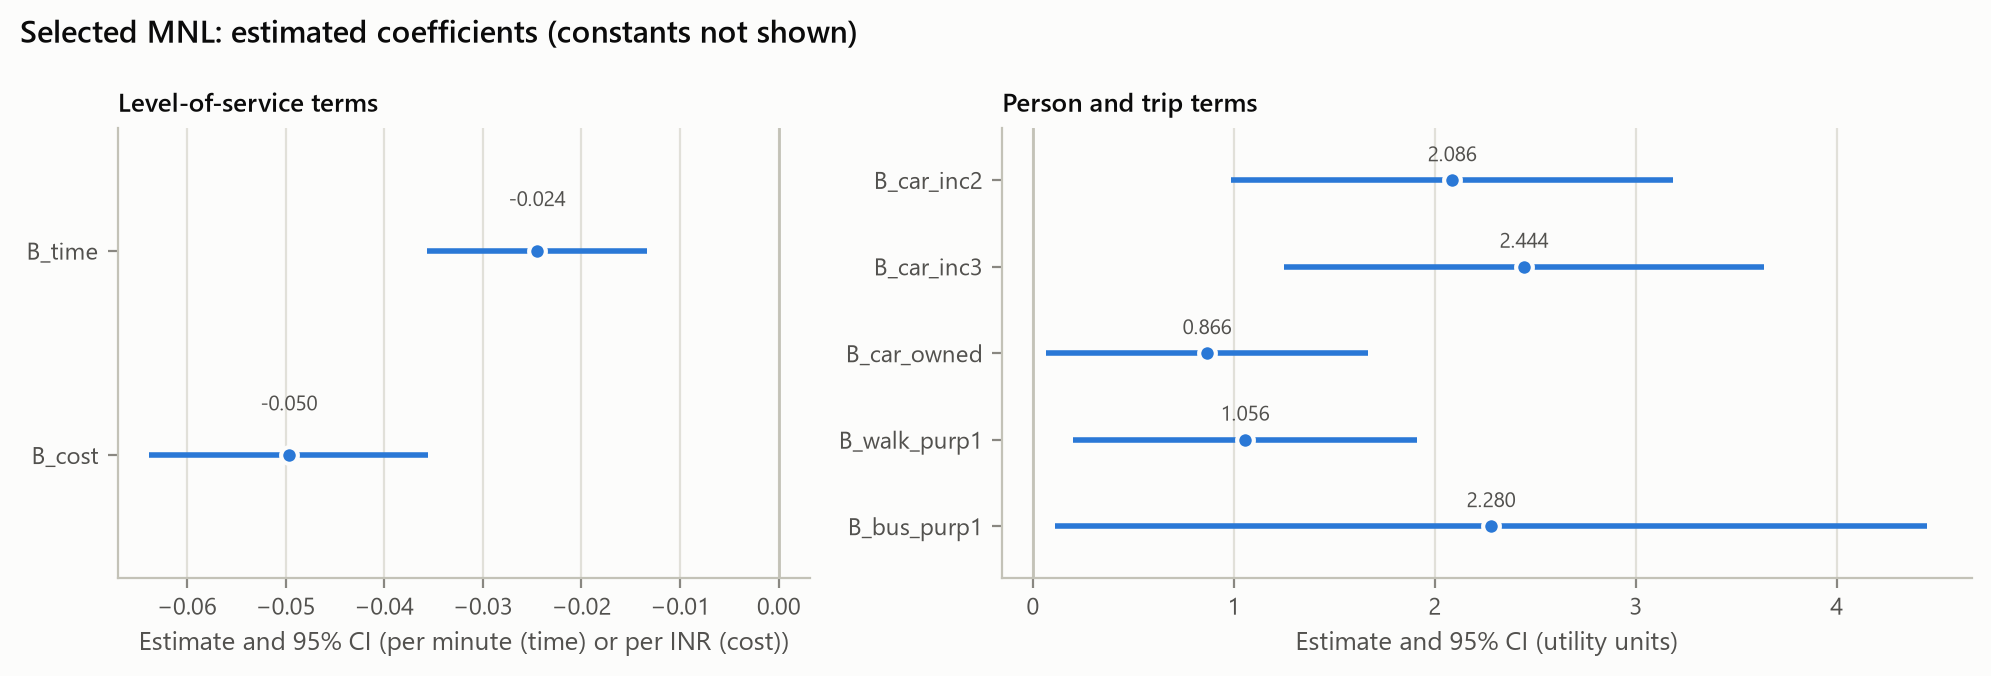

In [4]:
fig("mnl_coefficients.png", 850)

Time (-0.024 per minute) and cost (-0.050 per rupee) are negative and significant, giving a value of
in-vehicle time of about INR 30 per hour. Higher income and more cars raise car utility; purpose code 1
raises walking and bus utility.

## Nested logit

In [5]:
pd.read_csv(RES / "nested_logit_structures.csv")

,structure,log_likelihood,lambdas,lambda_se,lambda_at_bound,p_lambda_below_1,LR_vs_MNL,LR_p_value,usable
0,"PT{bus,train}",-350.959,{'bus_train': np.float64(0.05)},[0.15],[True],[0.0],14.883,0.0001,False
1,"PT{bus,train} + PRIVATE{car,twow}",-350.959,"{'bus_train': np.float64(0.05), 'car_twow': np.float64(1.0)}","[0.151, 0.155]","[True, True]","[0.0, 0.5]",14.883,0.0006,False
2,"SHARED{auto,bus,train}",-354.092,{'auto_bus_train': np.float64(0.537)},[0.119],[False],[0.0001],8.617,0.0033,True
3,"SHARED{auto,bus,train} + PRIVATE{car,twow}",-354.092,"{'auto_bus_train': np.float64(0.537), 'car_twow': np.float64(1.0)}","[0.13, 0.184]","[False, True]","[0.0002, 0.5]",8.617,0.0135,False
4,"MOTORISED{twow,auto,car,bus,train}",-358.400,{'twow_auto_car_bus_train': np.float64(1.0)},[0.265],[True],[0.5],-0.000,1.0000,False


Five nesting structures were estimated. A {bus, rail} nest drives its scale parameter to the lower
bound, a sign of separation in the small bus-versus-rail sub-sample, so it is not usable. A private
{car, two-wheeler} nest pushes lambda to 1 or above (no nesting, or inconsistent with random utility).
The only usable structure is a "shared/public" nest {auto, bus, rail}: lambda = 0.537 (s.e. 0.119),
significantly below 1, likelihood-ratio test against the MNL p = 0.003.

## Tuning results

In [6]:
pd.read_csv(RES / "tuning_results.csv")[["model", "configurations", "best_cv_macro_f1", "best_params"]]

,model,configurations,best_cv_macro_f1,best_params
0,MNL,3,0.559415,"{""spec"": ""GC+CORE""}"
1,Logistic regression,22,0.622330,"{""balanced"": true, ""estimator__clf__C"": 0.01}"
2,Decision tree,640,0.630271,"{""balanced"": false, ""estimator__clf__criterion"": ""entropy"", ""estimator__clf_..."
3,Random forest,60,0.621201,"{""estimator__clf__n_estimators"": 200, ""estimator__clf__min_samples_split"": 1..."
4,XGBoost,60,0.628515,"{""estimator__clf__subsample"": 1.0, ""estimator__clf__reg_lambda"": 10.0, ""esti..."
5,Nested logit,5,NaN,"{""spec"": ""GC+CORE"", ""nests"": ""SHARED{auto,bus,train}""}"


## Cross-validated comparison (training partition, 25 folds)

In [7]:
cv = pd.read_csv(RES / "cv_summary.csv", index_col=0)
cols = ["accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1", "balanced_accuracy",
        "log_loss", "brier", "ece", "share_mae_pp"]
display(pd.DataFrame({c: cv[f"{c}_mean"] for c in cols}).round(3))
pd.DataFrame({c: cv[f"{c}_sd"] for c in ["macro_f1", "balanced_accuracy", "log_loss"]}).round(3)

,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,balanced_accuracy,log_loss,brier,ece,share_mae_pp
model,,,,,,,,,,
MNL,0.628,0.671,0.570,0.562,0.603,0.570,0.915,0.487,0.098,1.607
Nested logit,0.623,0.658,0.566,0.556,0.596,0.566,0.925,0.486,0.098,1.772
Logistic regression,0.620,0.632,0.630,0.607,0.626,0.630,0.907,0.507,0.134,4.978
Decision tree,0.650,0.656,0.613,0.617,0.643,0.613,2.071,0.524,0.168,1.911
Random forest,0.661,0.720,0.585,0.601,0.644,0.585,0.863,0.480,0.110,2.813
XGBoost,0.679,0.690,0.611,0.620,0.661,0.611,0.784,0.441,0.091,1.670
Reference: constants only,0.550,0.393,0.466,0.396,0.477,0.466,1.052,0.584,0.075,1.474


,macro_f1,balanced_accuracy,log_loss
model,,,
MNL,0.050,0.043,0.128
Nested logit,0.065,0.055,0.152
Logistic regression,0.047,0.055,0.048
Decision tree,0.072,0.071,0.602
Random forest,0.075,0.070,0.090
XGBoost,0.064,0.054,0.075
Reference: constants only,0.023,0.016,0.037


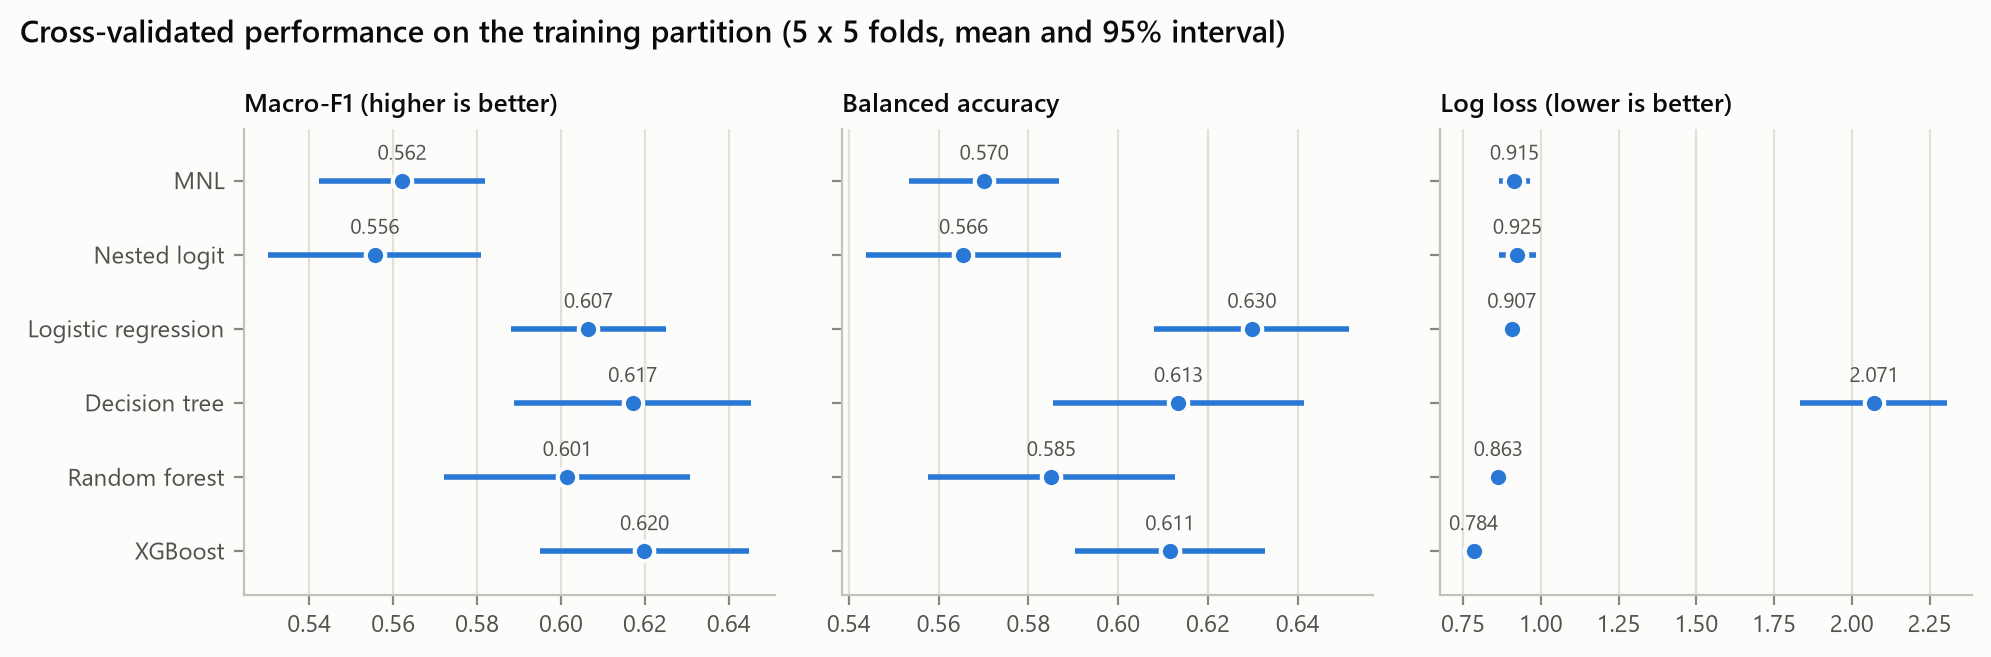

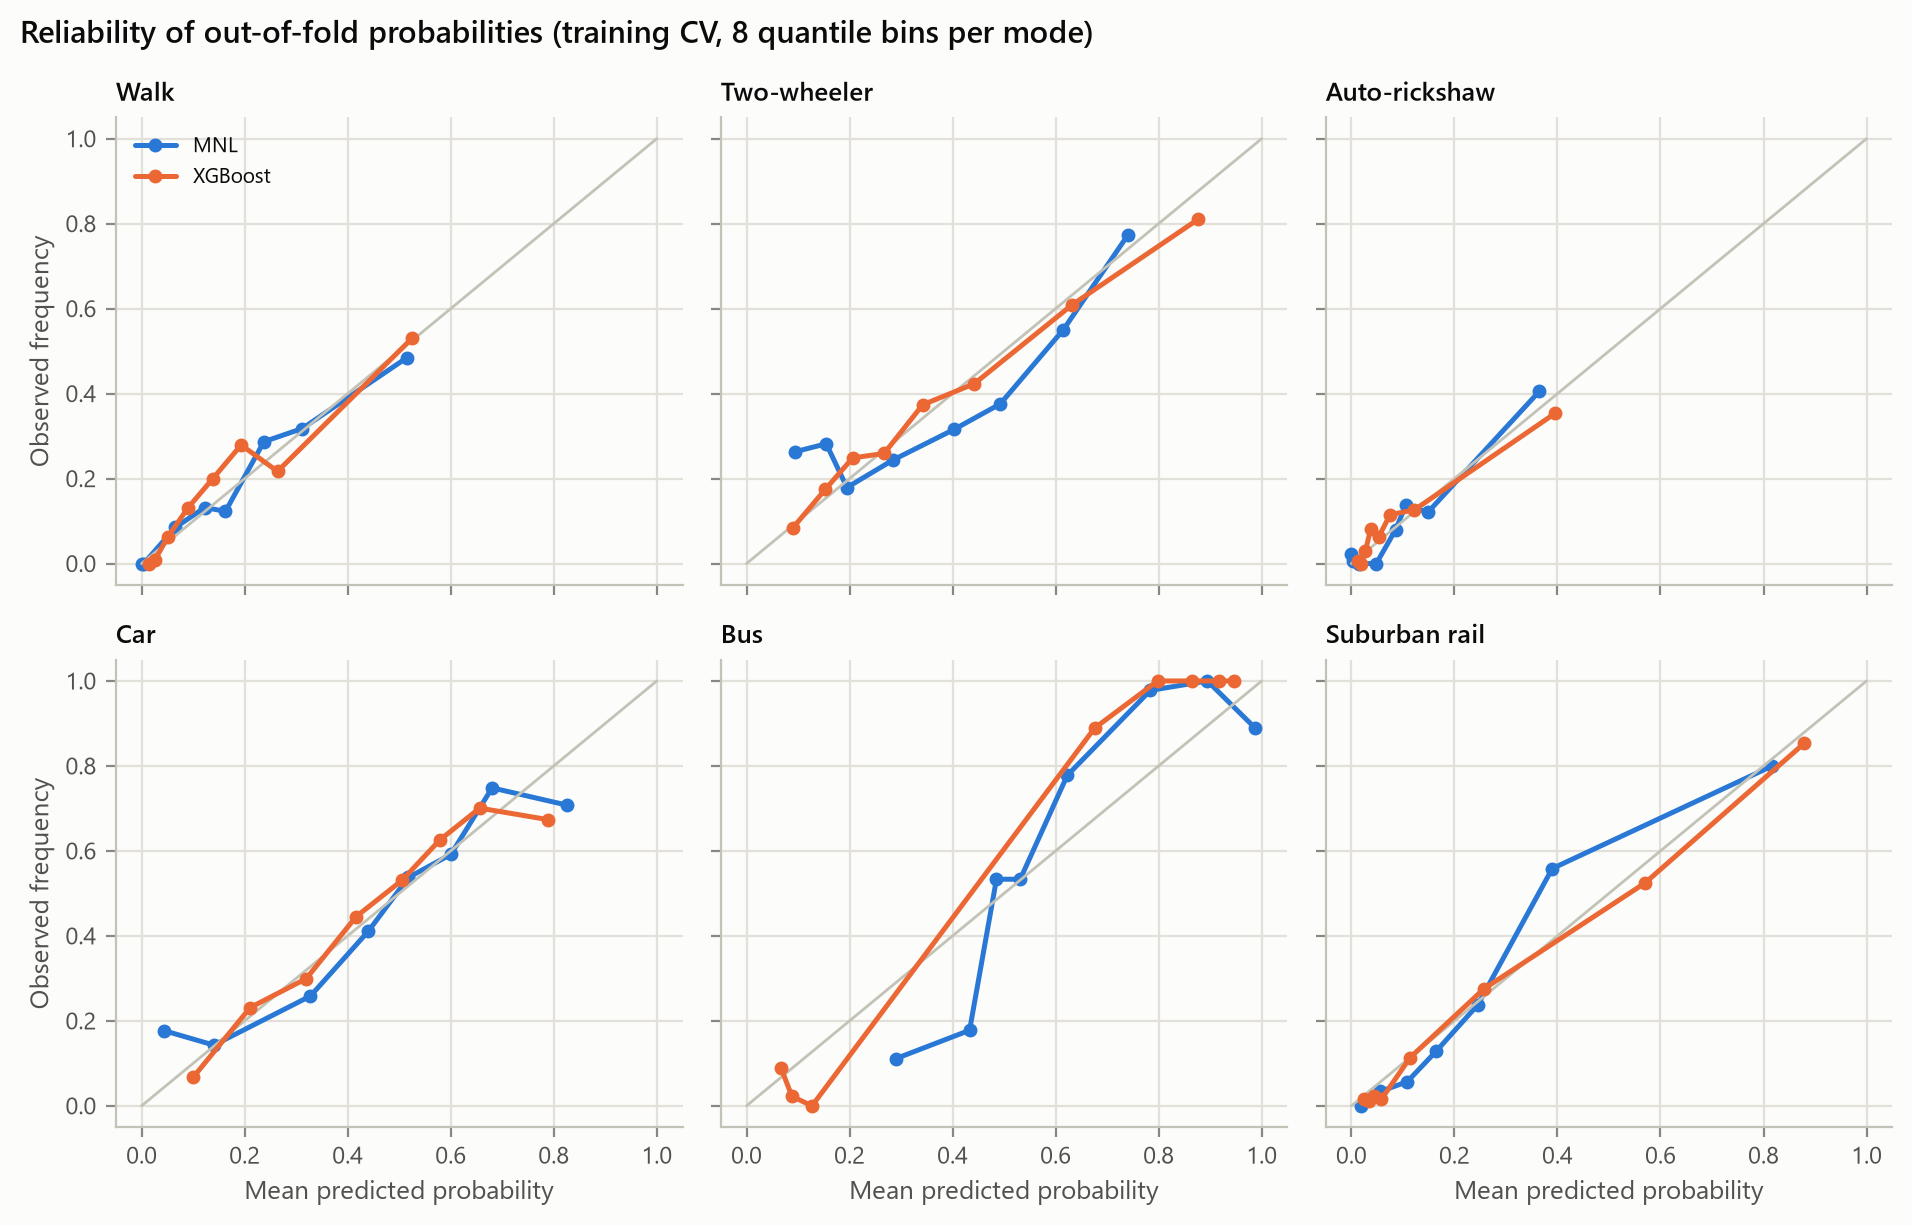

In [8]:
fig("model_cv_comparison.png", 950)
fig("model_calibration.png", 850)

XGBoost has the best cross-validated macro-F1 (0.620) and the lowest log loss (0.784). The MNL is
clearly behind on classification (macro-F1 0.562) but still far better than the constants-only
reference (0.396). Logistic regression with balanced class weights reaches a high balanced
accuracy, at the price of distorted aggregate shares (share error 5.0 pp against 1.6 for the MNL).

## Simulation readiness

The frozen model's job is to answer "what if bus fares fall by 20%?". A model that gives the wrong
sign, or no answer at all, cannot do that job however well it classifies.

lever,bus fare,bus time,car cost,rail fare,rail time
model,,,,,
Decision tree,0.000,-1.118,-1.072,0.000,0.000
Logistic regression,-0.300,-0.059,-0.127,0.027,-0.314
MNL,2.378,1.825,-3.804,0.593,0.873
Nested logit,2.214,1.921,-3.328,0.505,0.818
Random forest,-0.077,-0.215,-0.151,0.000,-0.277
XGBoost,0.000,0.000,0.000,0.000,0.000


lever,bus fare,bus time,car cost,rail fare,rail time
model,,,,,
Decision tree,0.000,0.083,0.009,0.000,0.000
Logistic regression,0.847,0.847,0.468,0.465,0.986
MNL,0.000,0.000,0.000,0.000,0.000
Nested logit,0.000,0.000,0.000,0.000,0.000
Random forest,0.194,0.361,0.081,0.000,0.439
XGBoost,0.000,0.000,0.000,0.000,0.000


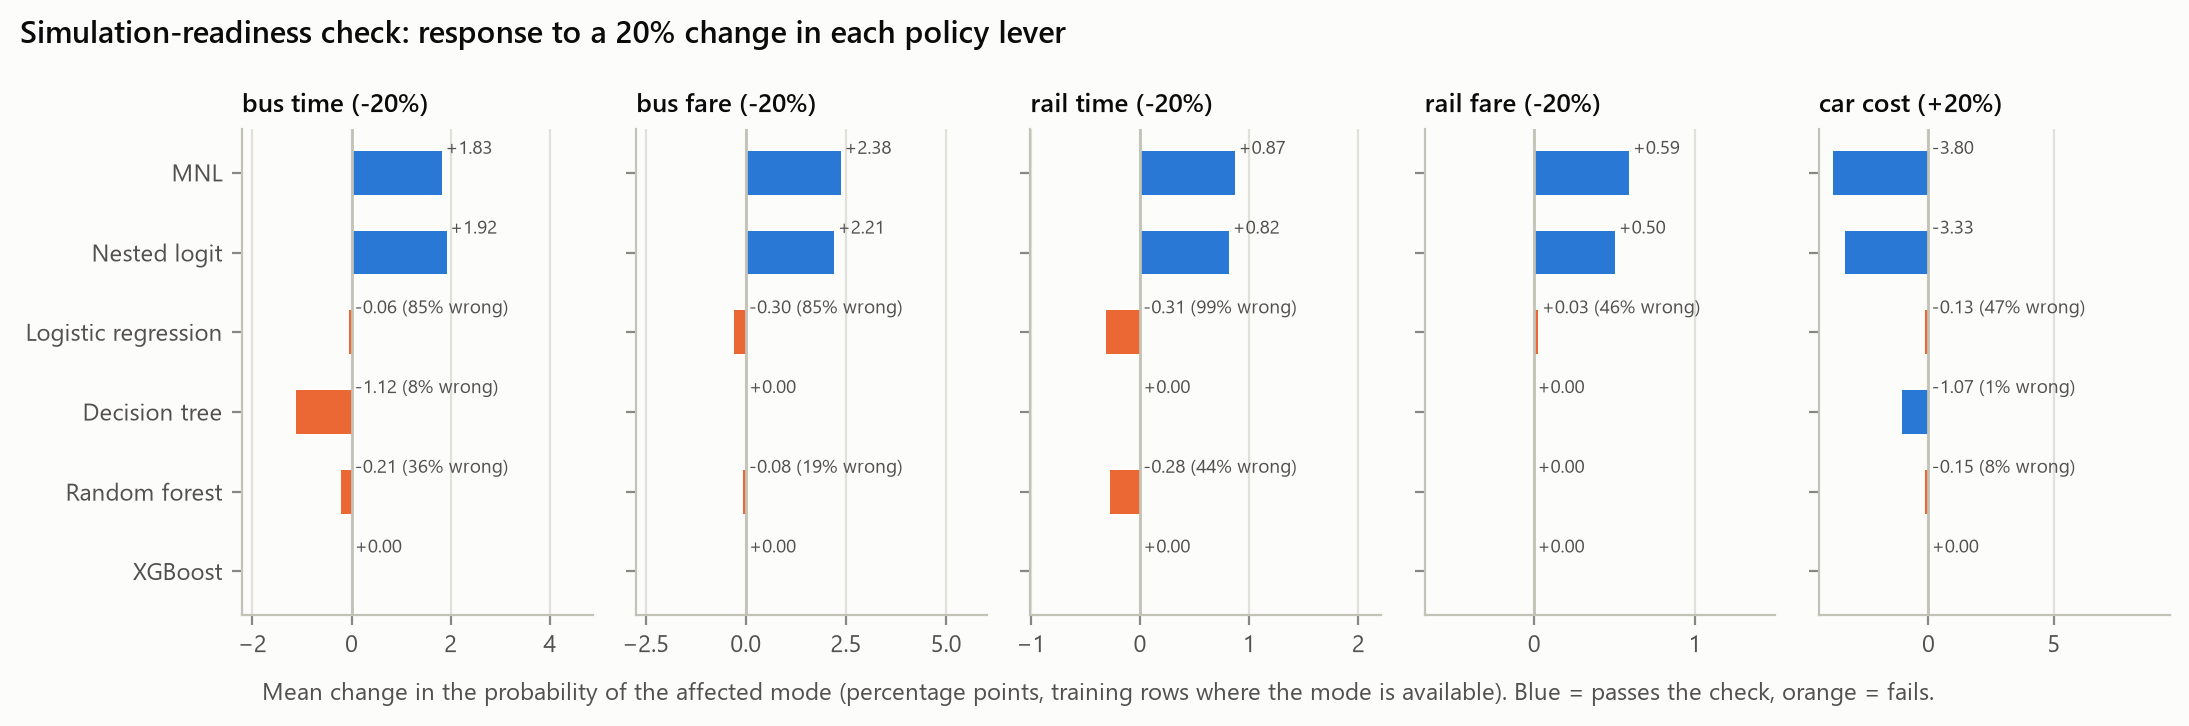

In [9]:
r = pd.read_csv(RES / "simulation_readiness.csv")
display(r.pivot(index="model", columns="lever", values="mean_change_pp").round(3))
display(r.pivot(index="model", columns="lever", values="share_wrong_direction").round(3))
fig("model_simulation_readiness.png", 1000)

Only the two logit models respond to every lever in the direction theory requires. The tuned XGBoost
never splits on any policy variable (distance carries the same information), so its predictions do
not move at all. Logistic regression and the random forest learned that longer bus or rail times go
with more bus or rail use, because both rise with distance, so a faster bus or train makes that mode
*less* likely for 36-99% of the people who have it. The decision tree also lowers bus use when bus
time falls.

## Selection

In [10]:
print(json.dumps(json.load(open(RES / "model_selection.json")), indent=1))

{
 "ranking": [
  "XGBoost",
  "Decision tree",
  "Logistic regression",
  "Random forest",
  "MNL",
  "Nested logit"
 ],
 "shortlist_after_f1_and_ba": [
  "Decision tree",
  "XGBoost"
 ],
 "skipped": [
  "XGBoost",
  "Decision tree",
  "Logistic regression",
  "Random forest"
 ],
 "winner": "MNL",
 "readiness": {
  "MNL": true,
  "Nested logit": true,
  "Logistic regression": false,
  "Decision tree": false,
  "Random forest": false,
  "XGBoost": false
 }
}


Following the rule written down before fitting, XGBoost and the decision tree form the predictive
shortlist, but every machine-learning model fails the readiness check, so the MNL is selected and
frozen. Had the readiness check been left out, XGBoost would have been chosen.

## Held-out test set

,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,balanced_accuracy,log_loss,brier,ece,share_mae_pp
model,,,,,,,,,,
MNL,0.523,0.530,0.461,0.451,0.504,0.461,0.949,0.553,0.102,1.165
Nested logit,0.495,0.505,0.432,0.427,0.476,0.432,0.932,0.547,0.122,1.489
Logistic regression,0.551,0.569,0.564,0.558,0.565,0.564,0.942,0.531,0.047,4.011
Decision tree,0.673,0.736,0.613,0.620,0.660,0.613,1.877,0.472,0.138,0.883
Random forest,0.598,0.688,0.532,0.548,0.585,0.532,0.904,0.515,0.079,1.823
XGBoost,0.682,0.746,0.598,0.605,0.659,0.598,0.781,0.428,0.124,0.952
Reference: constants only,0.523,0.372,0.449,0.375,0.462,0.449,1.094,0.610,0.067,1.405


{'accuracy': [0.42990654205607476, 0.6261682242990654], 'macro_f1': [0.3489665885585003, 0.5576780025025619], 'balanced_accuracy': [0.38133451923893097, 0.5537083333333334], 'log_loss': [0.8173606656621257, 1.0803941155917582]}


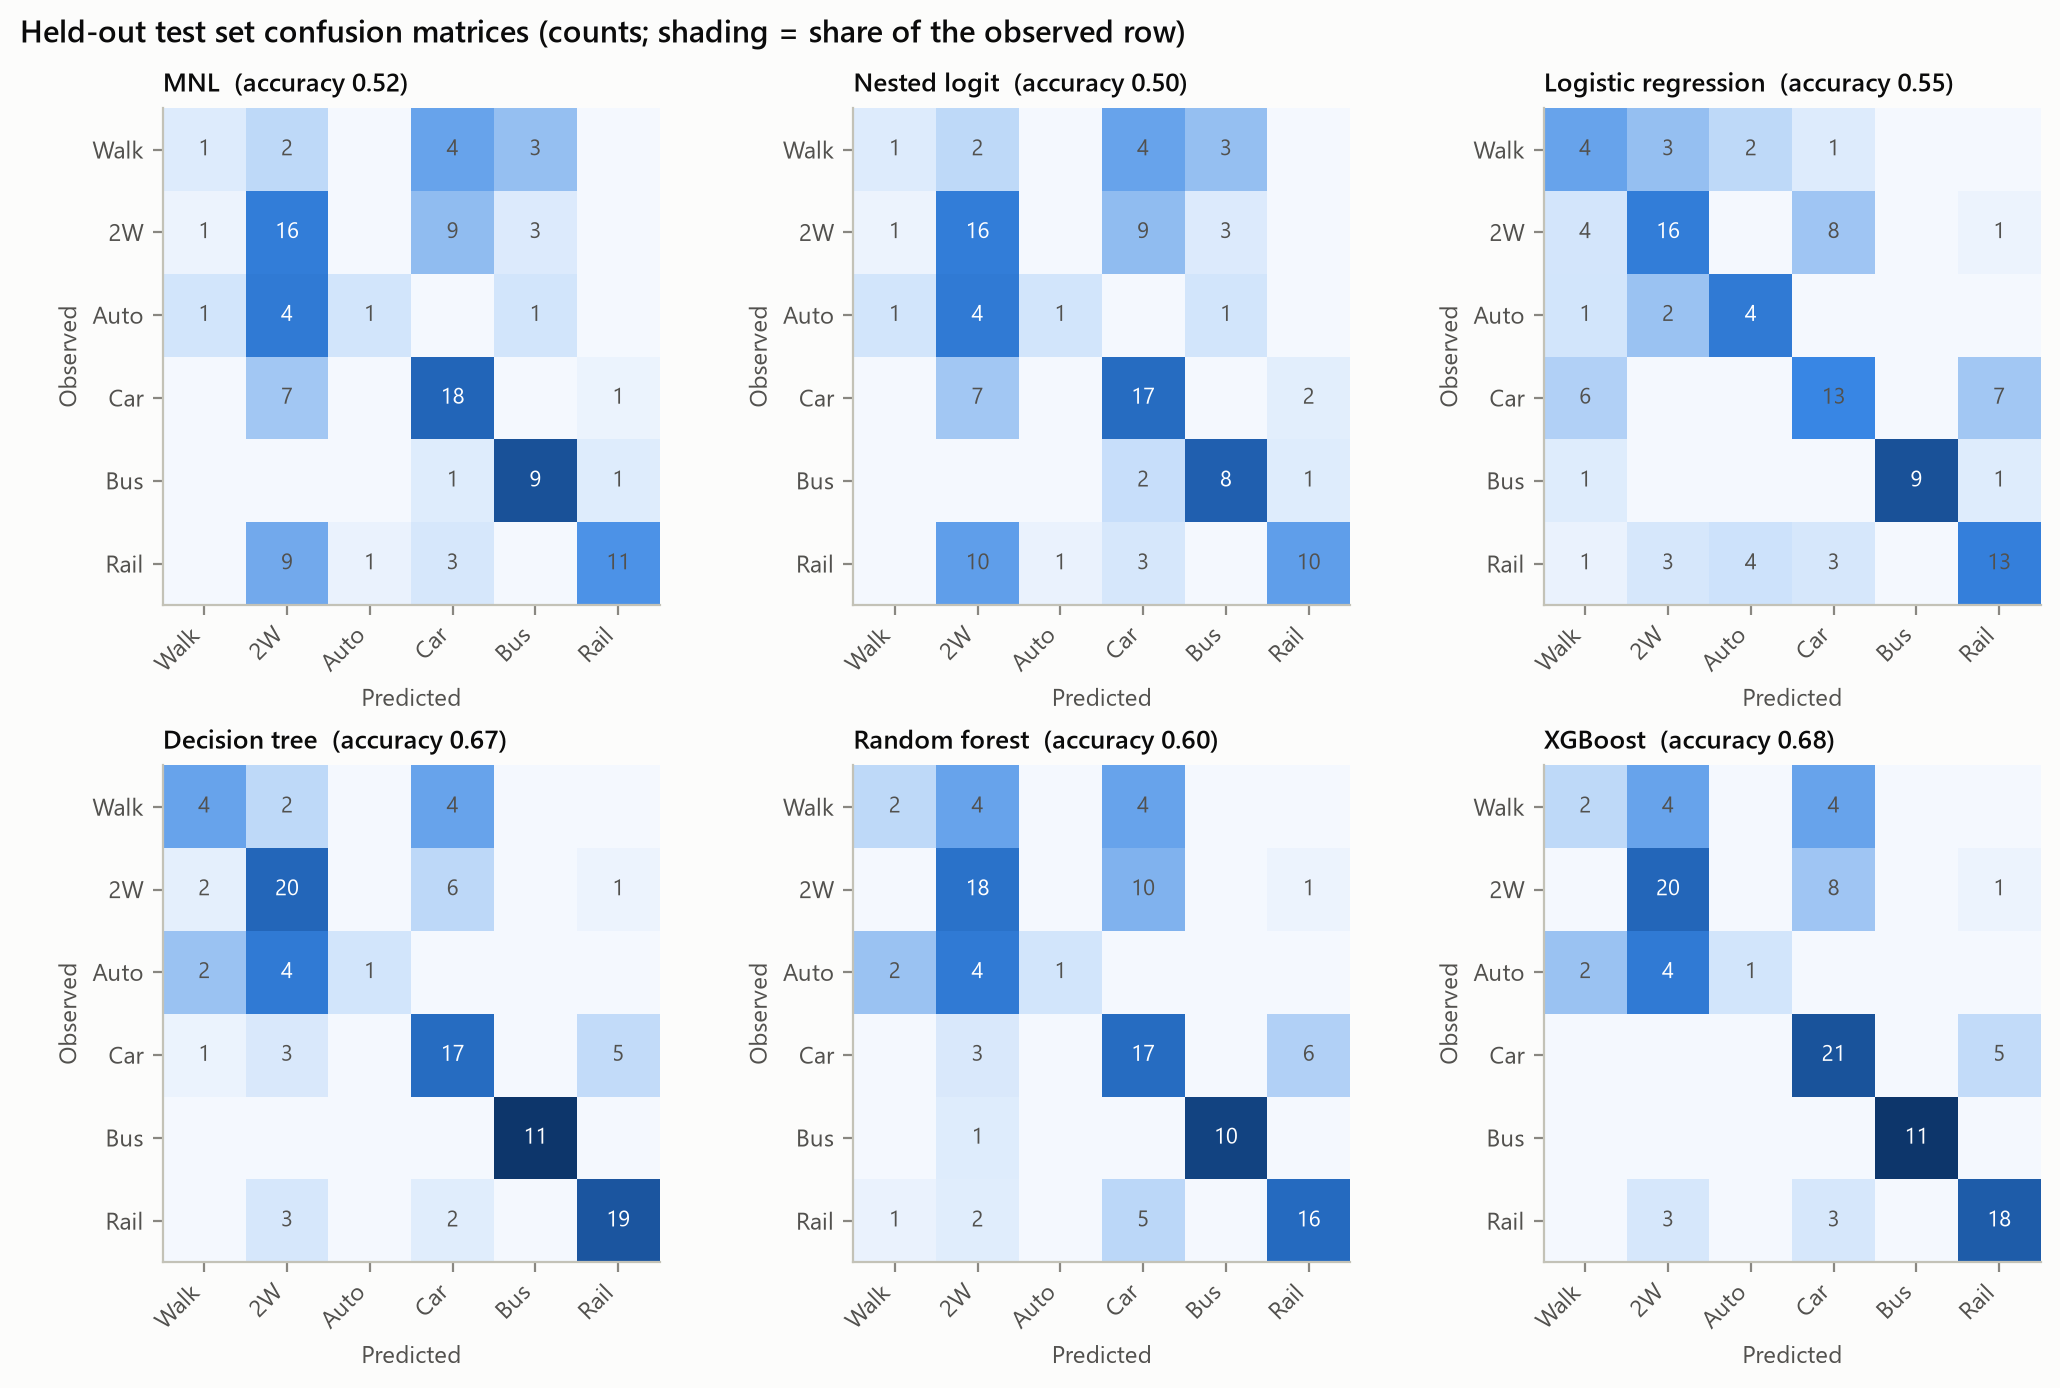

In [11]:
test = pd.read_csv(RES / "test_metrics.csv", index_col=0)
display(test.round(3))
print(json.load(open(RES / "test_bootstrap_ci.json"))["MNL"])
fig("model_confusion_matrices.png", 950)

On the 107 test records the MNL does worse than its cross-validation suggested (macro-F1 0.451,
bootstrap 95% CI 0.35-0.56), and its accuracy equals that of the constants-only reference, although
its log loss (0.949 vs 1.094) is clearly better. XGBoost and the decision tree classify the test set
much better. We report this as it is: the frozen model is the best model for *simulation*, not the
best classifier.

Refitting the frozen configuration on the training rows reproduces the frozen model exactly, which
confirms that nothing from the test set was used in fitting:

In [12]:
from sklearn.base import clone
from src.prediction import load_frozen
from src import preprocessing as PP
model, card = load_frozen()
train = pd.read_csv(C.Paths().processed / "train.csv"); test_df = pd.read_csv(C.Paths().processed / "test.csv")
refit = clone(model).fit(train, PP.target(train))
print("max abs difference in test probabilities:", np.abs(refit.predict_proba(test_df) - model.predict_proba(test_df)).max())

max abs difference in test probabilities: 0.0
